## Chargement des données

In [5]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("maqdadali/mental-health-risk-prediction-dataset-students")

print("Path to dataset files:", path)

Using Colab cache for faster access to the 'mental-health-risk-prediction-dataset-students' dataset.
Path to dataset files: /kaggle/input/mental-health-risk-prediction-dataset-students


In [6]:
import shutil

shutil.copytree(
    path,
    "data/raw",
    dirs_exist_ok=True
)

print("Dataset copié dans data/raw/")

Dataset copié dans data/raw/


In [7]:
import glob

csv_files = glob.glob("data/raw/**/*.csv", recursive=True)


In [8]:
import pandas as pd

df = pd.read_csv(csv_files[0])

display(df.head())
print("Dimensions :", df.shape)
print("\nTypes des colonnes :")
display(df.dtypes)

,Student_ID,Age,Gender,Year_of_Study,Sleep_Hours,Study_Hours_Per_Week,GPA,Social_Media_Hours,Screen_Time_Hours,Physical_Activity,Financial_Stress,Family_Support,Attendance_Rate,Part_Time_Job,Diet_Quality,Previous_Mental_Health_History,Mental_Health_Risk
0,STU0001,22,Male,3,6.6,17.6,2.91,6.9,7.5,Moderate,8.5,4.0,78.0,No,Poor,No,High
1,STU0002,21,Male,4,5.6,22.4,2.92,7.6,11.5,Low,4.5,5.3,85.4,Yes,Average,No,Medium
2,STU0003,22,Male,5,7.1,28.1,2.68,6.5,8.9,Low,4.8,6.1,79.5,No,Average,No,Medium
3,STU0004,24,Male,1,4.5,14.8,2.23,5.5,7.6,High,3.7,8.0,73.9,No,Average,Yes,High
4,STU0005,20,Female,1,6.7,17.2,2.69,4.3,7.0,Moderate,8.0,7.4,99.8,Yes,NaN,No,Medium


Dimensions : (2000, 17)

Types des colonnes :


,0
Student_ID,object
Age,int64
Gender,object
Year_of_Study,int64
Sleep_Hours,float64
Study_Hours_Per_Week,float64
GPA,float64
Social_Media_Hours,float64
Screen_Time_Hours,float64
Physical_Activity,object


## Statistiques descriptives

In [6]:
df.describe()

,Age,Year_of_Study,Sleep_Hours,Study_Hours_Per_Week,GPA,Social_Media_Hours,Screen_Time_Hours,Financial_Stress,Family_Support,Attendance_Rate
count,2000.000000,2000.000000,1938.000000,2000.000000,1962.000000,1942.000000,2000.000000,1909.000000,1946.000000,1953.000000
mean,21.131500,2.630000,6.758875,19.997900,2.562503,6.013955,8.548500,5.956260,6.518345,85.080236
std,2.139275,1.316802,1.127072,5.719274,0.343993,1.153422,1.657571,1.893941,1.844639,7.224118
min,17.000000,1.000000,3.300000,2.400000,1.500000,2.100000,3.300000,1.400000,1.700000,54.400000
25%,20.000000,1.000000,6.000000,16.000000,2.320000,5.225000,7.400000,4.500000,5.100000,80.300000
50%,21.000000,2.000000,6.700000,19.800000,2.560000,6.000000,8.500000,6.100000,6.700000,85.100000
75%,23.000000,4.000000,7.600000,24.000000,2.790000,6.700000,9.700000,7.400000,8.000000,90.000000
max,29.000000,5.000000,10.000000,38.300000,3.660000,10.000000,14.000000,10.000000,9.900000,100.000000


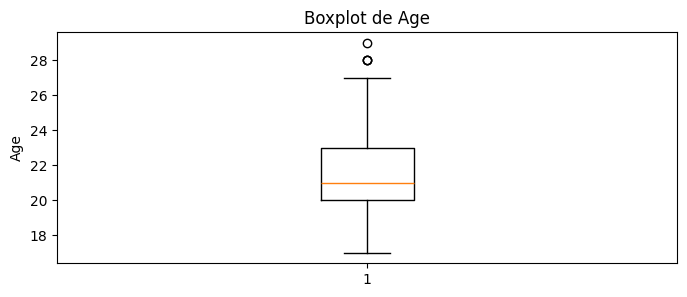

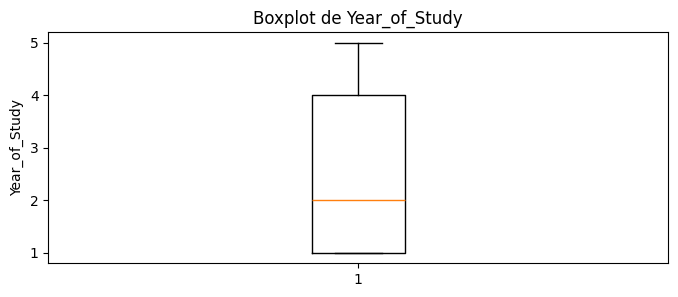

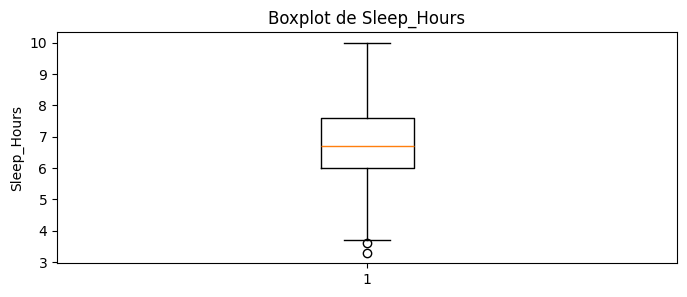

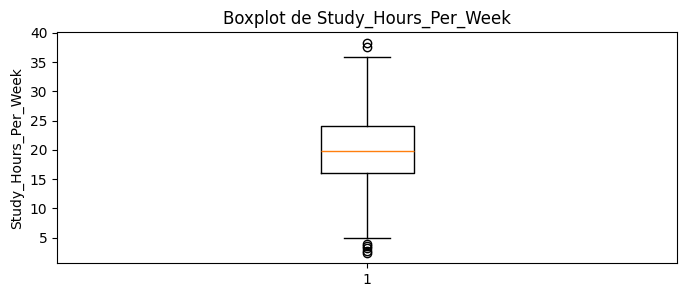

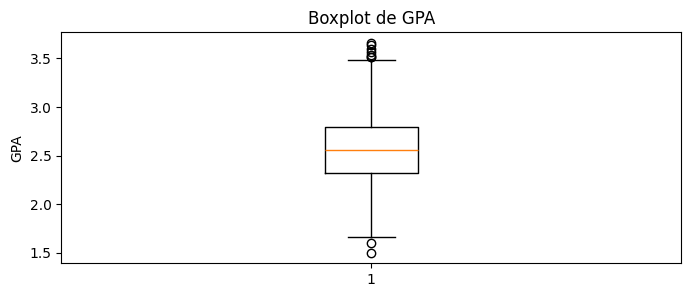

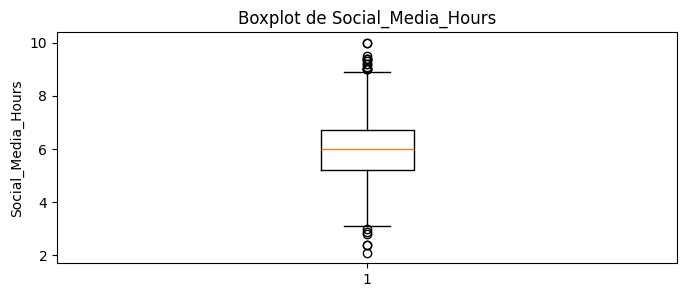

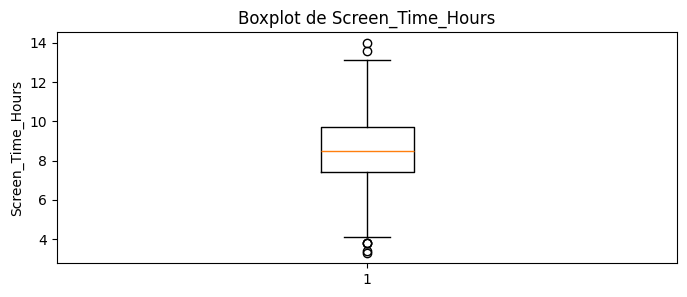

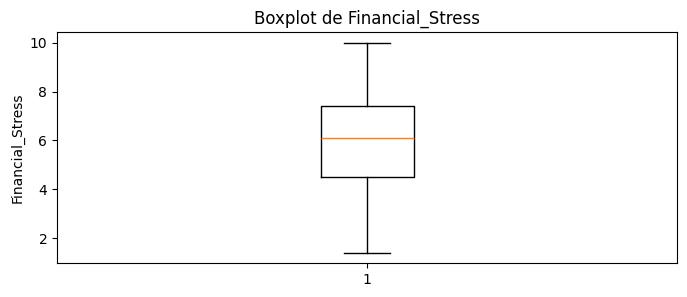

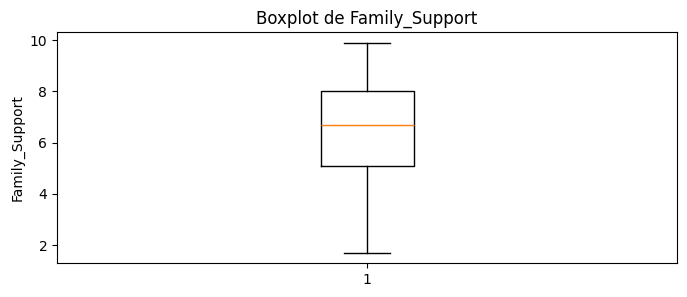

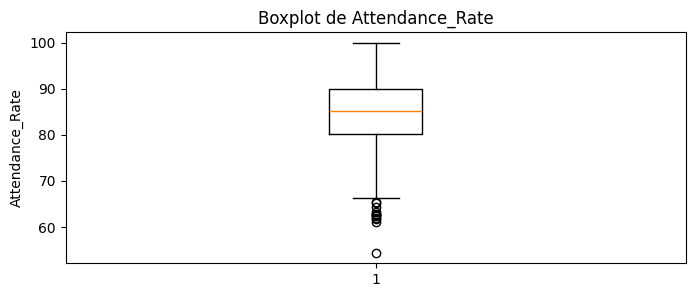

In [7]:
# Distribution des variables numériques
import matplotlib.pyplot as plt

val_numeric= [
    "Age",
    "Year_of_Study",
    "Sleep_Hours",
    "Study_Hours_Per_Week",
    "GPA",
    "Social_Media_Hours",
    "Screen_Time_Hours",
    "Financial_Stress",
    "Family_Support",
    "Attendance_Rate"
]

for val in val_numeric:

    plt.figure(figsize=(8, 3))

    plt.boxplot(df[val].dropna())

    plt.title(f"Boxplot de {val}")
    plt.ylabel(val)

    plt.show()

In [8]:
categorical_columns = [
    "Gender",
    "Physical_Activity",
    "Part_Time_Job",
    "Diet_Quality",
    "Previous_Mental_Health_History"
]

for col in categorical_columns:
    print("\n", "=" * 40)
    print(df[col].value_counts())


Gender
Female        971
Male          932
Non-binary     97
Name: count, dtype: int64

Physical_Activity
Moderate    906
Low         679
High        415
Name: count, dtype: int64

Part_Time_Job
No     1289
Yes     711
Name: count, dtype: int64

Diet_Quality
Average    860
Poor       587
Good       484
Name: count, dtype: int64

Previous_Mental_Health_History
No     1408
Yes     592
Name: count, dtype: int64


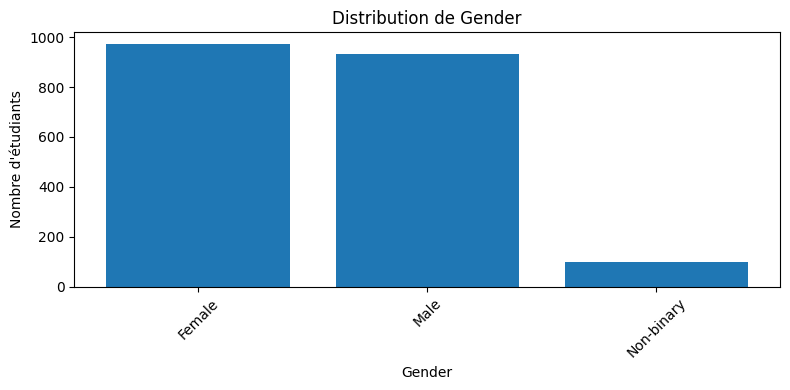

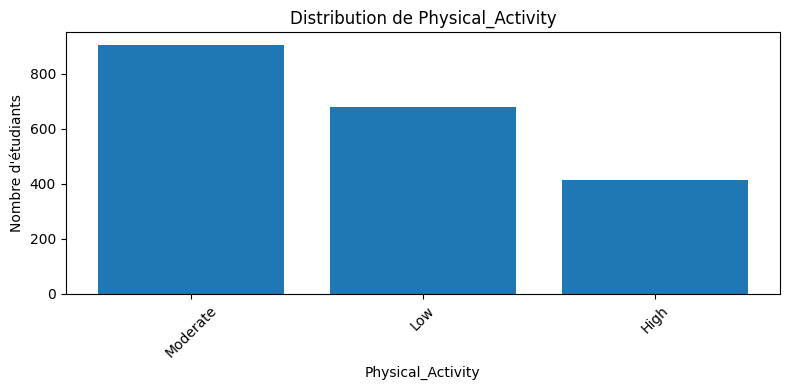

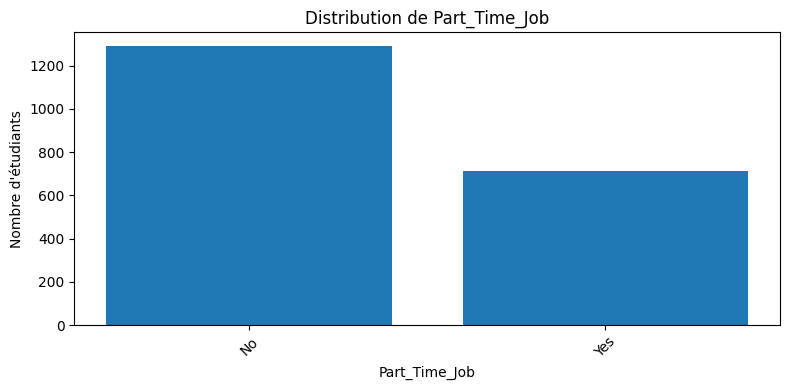

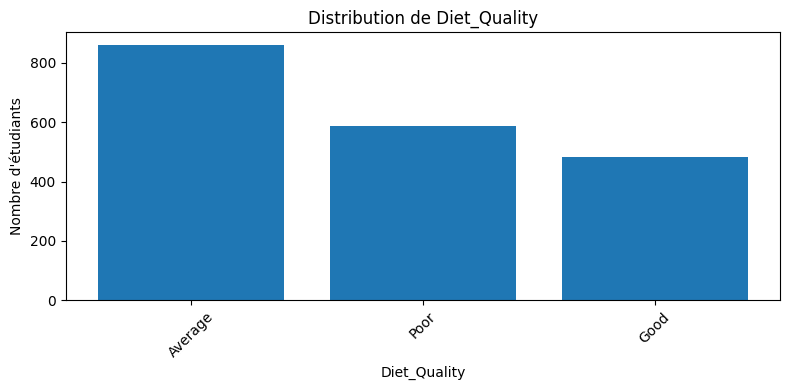

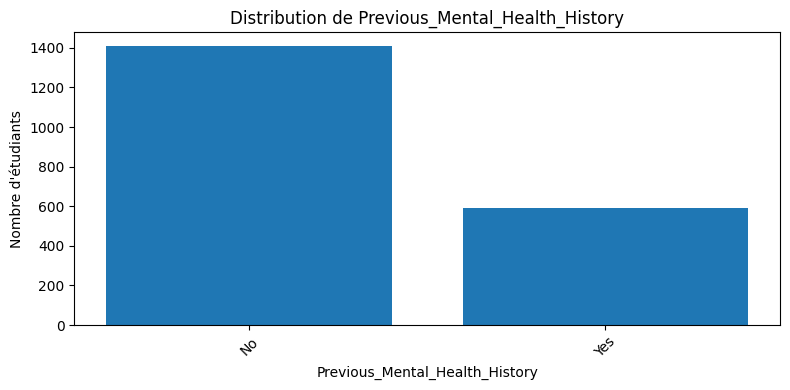

In [9]:
#Distribution des variables catégorielles
import matplotlib.pyplot as plt

for col in categorical_columns:

    counts = df[col].value_counts()

    plt.figure(figsize=(8, 4))
    plt.bar(counts.index, counts.values)

    plt.title(f"Distribution de {col}")
    plt.xlabel(col)
    plt.ylabel("Nombre d'étudiants")

    plt.xticks(rotation=45)
    plt.tight_layout()
    plt.show()

## Qualité des données

In [10]:
#  Valeurs manquantes
print("Total des valeurs manquantes :", df.isnull().sum())

Total des valeurs manquantes : Student_ID                         0
Age                                0
Gender                             0
Year_of_Study                      0
Sleep_Hours                       62
Study_Hours_Per_Week               0
GPA                               38
Social_Media_Hours                58
Screen_Time_Hours                  0
Physical_Activity                  0
Financial_Stress                  91
Family_Support                    54
Attendance_Rate                   47
Part_Time_Job                      0
Diet_Quality                      69
Previous_Mental_Health_History     0
Mental_Health_Risk                 0
dtype: int64


In [11]:
# Doublons
df.duplicated().sum()


np.int64(0)

In [12]:
df["Mental_Health_Risk"].value_counts(normalize=True) * 100

,proportion
Mental_Health_Risk,
High,34.0
Medium,33.0
Low,33.0


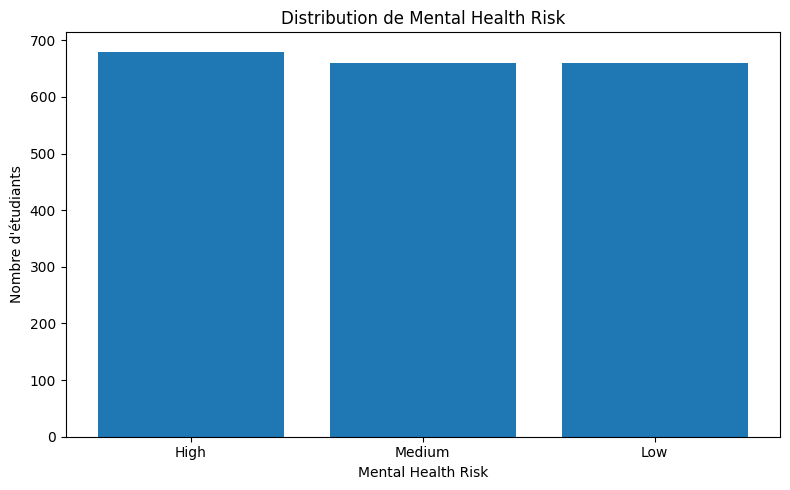

In [13]:
import matplotlib.pyplot as plt

counts = df["Mental_Health_Risk"].value_counts()

plt.figure(figsize=(8, 5))
plt.bar(counts.index, counts.values)

plt.title("Distribution de Mental Health Risk")
plt.xlabel("Mental Health Risk")
plt.ylabel("Nombre d'étudiants")

plt.tight_layout()
plt.show()

## Relations entre les variables explicatives et la cible

In [14]:

df.groupby("Mental_Health_Risk")[val_numeric].mean().T

Mental_Health_Risk,High,Low,Medium
Age,21.138235,21.112121,21.143939
Year_of_Study,2.360294,2.895455,2.642424
Sleep_Hours,6.035258,7.523648,6.729384
Study_Hours_Per_Week,18.362794,21.699697,19.980758
GPA,2.421604,2.718176,2.552099
Social_Media_Hours,6.345770,5.762773,5.922414
Screen_Time_Hours,8.960000,8.257424,8.415606
Financial_Stress,6.689697,5.243930,5.895024
Family_Support,5.956212,7.088438,6.527864
Attendance_Rate,83.767117,86.332293,85.191641


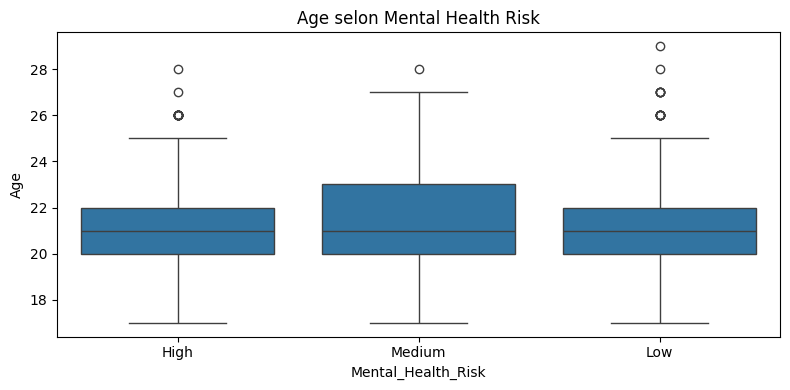

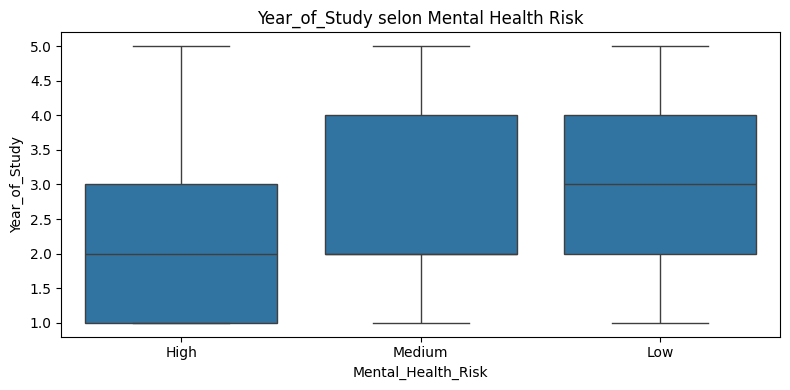

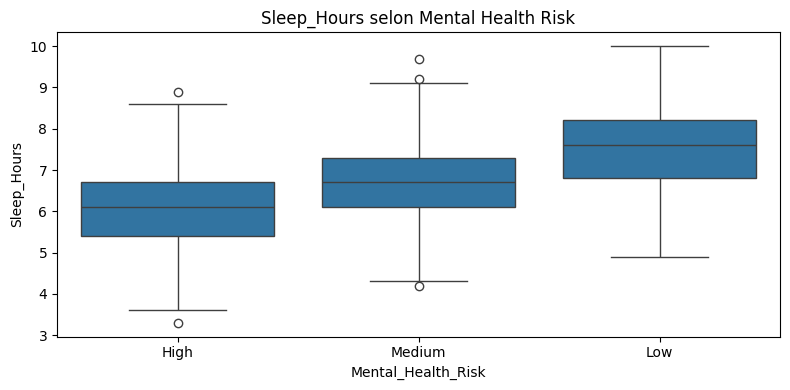

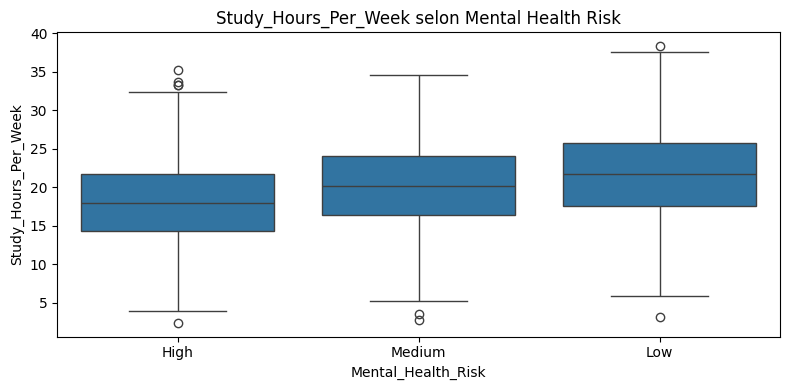

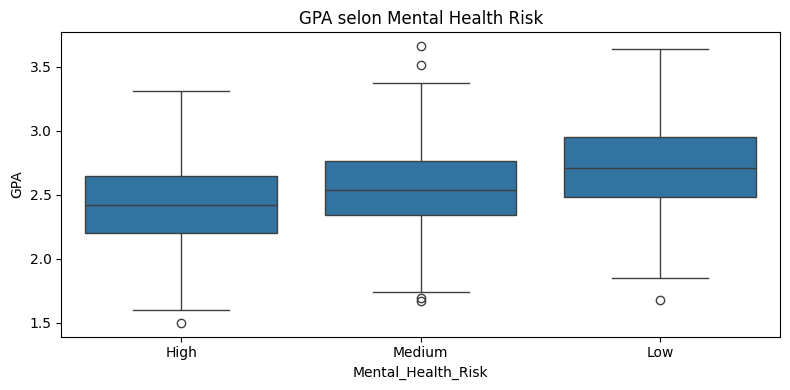

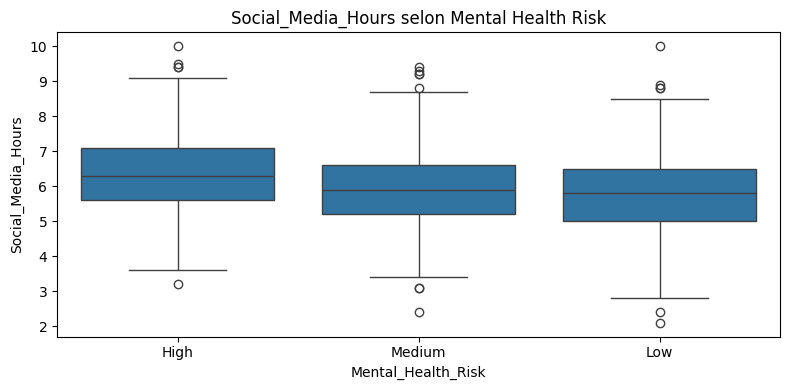

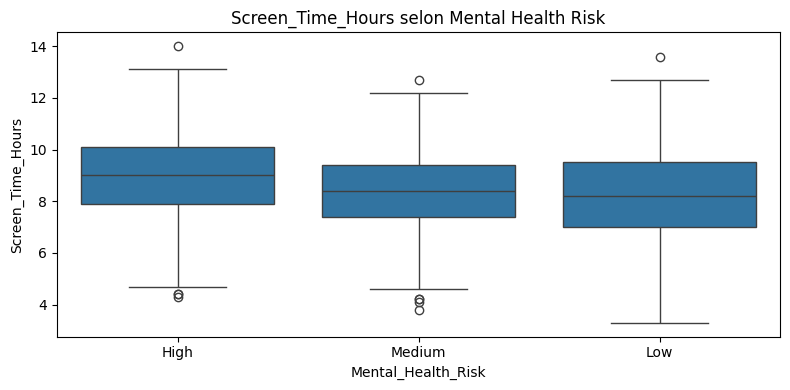

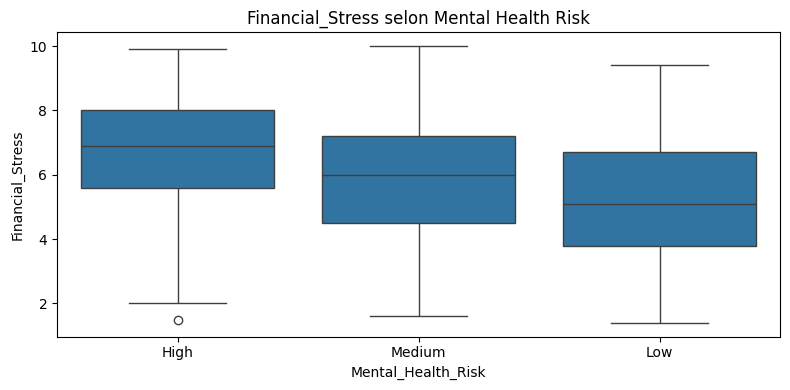

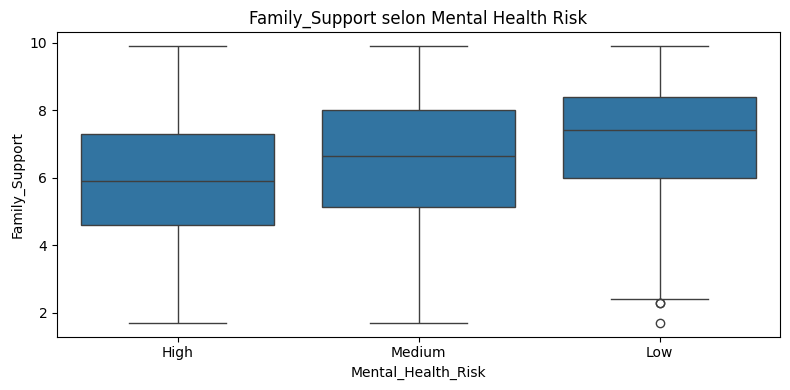

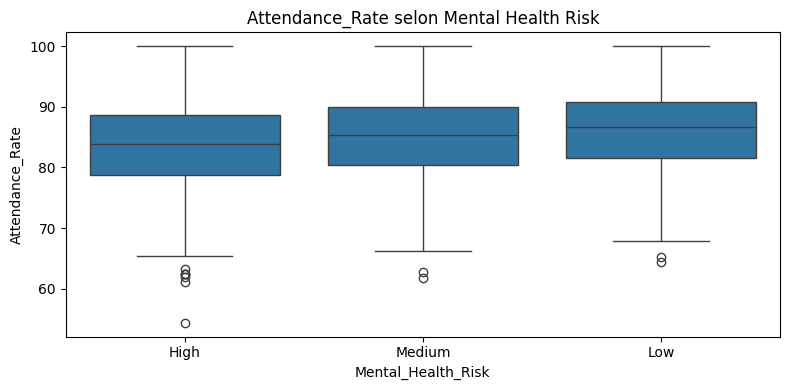

In [15]:
import seaborn as sns
import matplotlib.pyplot as plt
# Variables numériques selon le niveau de risque
for col in val_numeric:
    plt.figure(figsize=(8, 4))

    sns.boxplot(data=df, x="Mental_Health_Risk", y=col)

    plt.title(f"{col} selon Mental Health Risk")
    plt.tight_layout()
    plt.show()

In [16]:
#Variables catégorielles selon le niveau de risque
categorical_features = [
    "Gender",
    "Physical_Activity",
    "Part_Time_Job",
    "Diet_Quality",
    "Previous_Mental_Health_History"
]

In [17]:
for col in categorical_features:

    print(f"\nRépartition de Mental_Health_Risk selon {col} (%) :")

    cross_tab = pd.crosstab(
        df[col],
        df["Mental_Health_Risk"],
        normalize="index"
    )

    print((cross_tab * 100).round(2))


Répartition de Mental_Health_Risk selon Gender (%) :
Mental_Health_Risk   High    Low  Medium
Gender                                  
Female              34.60  33.47   31.93
Male                33.37  31.76   34.87
Non-binary          34.02  40.21   25.77

Répartition de Mental_Health_Risk selon Physical_Activity (%) :
Mental_Health_Risk   High    Low  Medium
Physical_Activity                       
High                20.24  49.40   30.36
Low                 45.95  22.83   31.22
Moderate            31.35  33.11   35.54

Répartition de Mental_Health_Risk selon Part_Time_Job (%) :
Mental_Health_Risk   High    Low  Medium
Part_Time_Job                           
No                  30.26  36.23   33.51
Yes                 40.79  27.14   32.07

Répartition de Mental_Health_Risk selon Diet_Quality (%) :
Mental_Health_Risk   High    Low  Medium
Diet_Quality                            
Average             32.33  33.49   34.19
Good                27.48  42.77   29.75
Poor                42

## Corrélations entre variables numériques

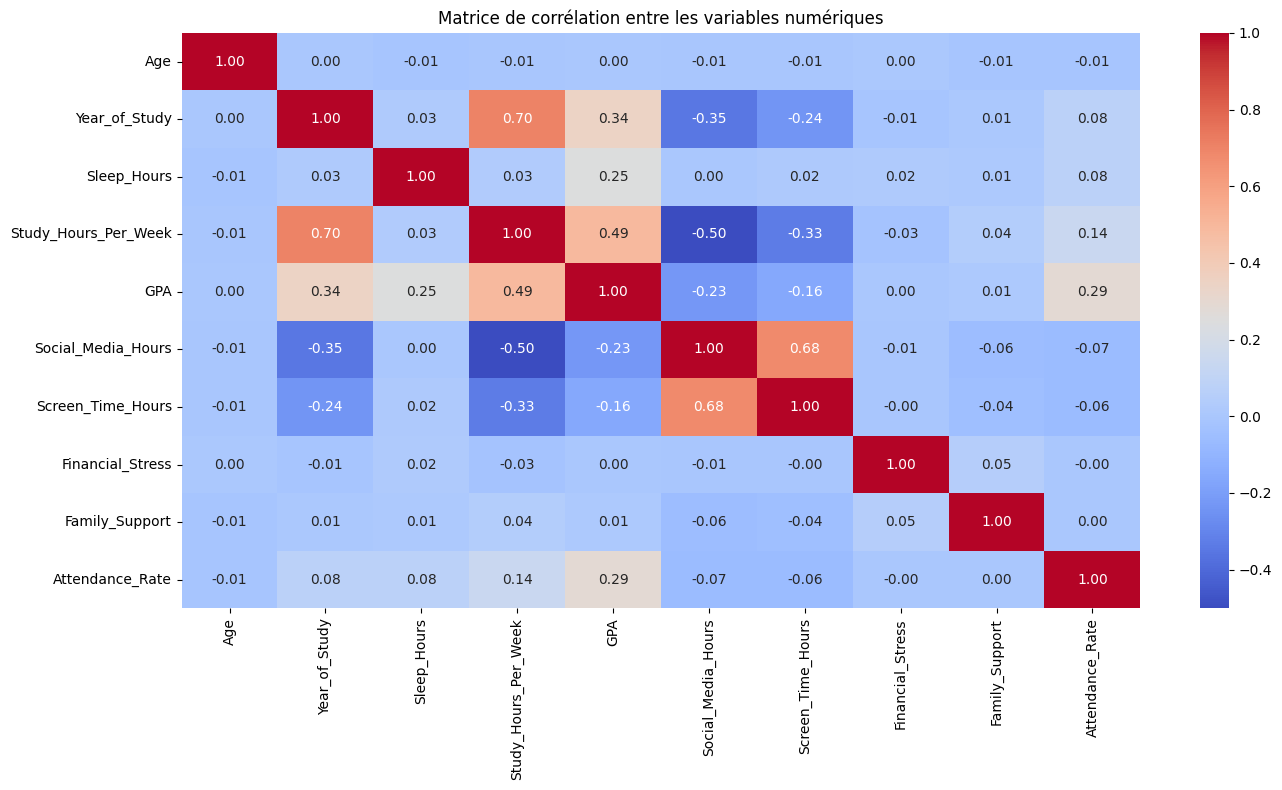

In [18]:
import seaborn as sns
import matplotlib.pyplot as plt


corr = df[val_numeric].corr()

plt.figure(figsize=(14, 8))

sns.heatmap(
    corr,
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Matrice de corrélation entre les variables numériques")
plt.tight_layout()
plt.show()